# Quickstart

Start with an interaction table, look at what annnet imported, select a subset,
and save the annotated graph. The example uses a small
[synthetic teaching dataset](guide/data/index.md): 11 interactions among 10
nodes, with two separately identified EGFR–GRB2 records.

Install annnet with [Polars](https://pola.rs/) tables, the native file format
and [Graphviz](https://graphviz.org/) plots:

```bash
pip install "annnet[polars,storage,graphviz]"
```

The Graphviz plots also need the `dot` program of Graphviz on your system.

## Load the table

Read the interaction table. The columns are `edge_id`, `source`, `target`,
`effect`, `confidence`, and `evidence`.

In [1]:
import annnet as an
import polars as pl
from annnet.utils.plotting import plot

interactions = pl.read_csv(
    'https://raw.githubusercontent.com/saezlab/annnet/main/docs/guide/data/interactions.csv'
)
interactions

edge_id,source,target,effect,confidence,evidence
str,str,str,i64,f64,str
"""egfr_grb2""","""EGFR""","""GRB2""",1,0.95,"""example_primary"""
"""egfr_grb2_alt""","""EGFR""","""GRB2""",1,0.65,"""example_alternative"""
"""grb2_sos1""","""GRB2""","""SOS1""",1,0.9,"""example_primary"""
"""sos1_ras""","""SOS1""","""RAS""",1,0.9,"""example_primary"""
"""ras_raf""","""RAS""","""RAF""",1,0.95,"""example_primary"""
…,…,…,…,…,…
"""mek_erk""","""MEK""","""ERK""",1,0.98,"""example_primary"""
"""erk_dusp6""","""ERK""","""DUSP6""",1,0.85,"""example_primary"""
"""dusp6_erk""","""DUSP6""","""ERK""",-1,0.9,"""example_primary"""


## Import the network

Map the identifier and effect columns explicitly, and put all interactions in
a slice named `prior`:

In [2]:
anet = an.from_edge_frame(
    interactions,
    edge_id='edge_id',
    sign='effect',
    directed=True,
    slice='prior',
)
anet.attrs.backend = 'polars'
anet.summary()

AnnNet summary: 10 node(s), 11 edge(s), 10 placement(s)
  directed default: True
  slices (2): default (0n/0e), prior (10n/11e)
  attrs: edges: ['sign', 'confidence', 'evidence']
  edges (computed): binary=11; directed=11, undirected=0

annnet creates the endpoint nodes and keeps both EGFR–GRB2 edges, because
they have different IDs. The `effect` column becomes the `sign` annotation.
Confidence stays an annotation; all structural weights are 1.

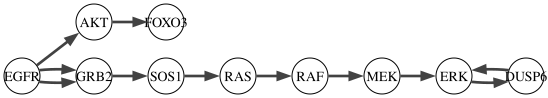

In [3]:
plot(anet, graph_attr={'rankdir': 'LR'})

## Inspect and select

The edge table shows the endpoints of each edge next to its annotations:

In [4]:
anet.attrs.table('edges', derived=True).select('edge_id', 'source', 'target', 'sign', 'confidence')

edge_id,source,target,sign,confidence
str,str,str,i64,f64
"""egfr_grb2""","""EGFR""","""GRB2""",1,0.95
"""egfr_grb2_alt""","""EGFR""","""GRB2""",1,0.65
"""grb2_sos1""","""GRB2""","""SOS1""",1,0.9
"""sos1_ras""","""SOS1""","""RAS""",1,0.9
"""ras_raf""","""RAS""","""RAF""",1,0.95
…,…,…,…,…
"""mek_erk""","""MEK""","""ERK""",1,0.98
"""erk_dusp6""","""ERK""","""DUSP6""",1,0.85
"""dusp6_erk""","""DUSP6""","""ERK""",-1,0.9


Which interactions have a confidence of at least 0.85?

In [5]:
supported = anet.E.select(confidence__gte=0.85)
confident = anet.view(edges=supported)
confident.attrs.table('edges', derived=True).select('edge_id', 'source', 'target', 'confidence')

edge_id,source,target,confidence
str,str,str,f64
"""egfr_grb2""","""EGFR""","""GRB2""",0.95
"""grb2_sos1""","""GRB2""","""SOS1""",0.9
"""sos1_ras""","""SOS1""","""RAS""",0.9
"""ras_raf""","""RAS""","""RAF""",0.95
"""raf_mek""","""RAF""","""MEK""",0.98
"""mek_erk""","""MEK""","""ERK""",0.98
"""erk_dusp6""","""ERK""","""DUSP6""",0.85
"""dusp6_erk""","""DUSP6""","""ERK""",0.9


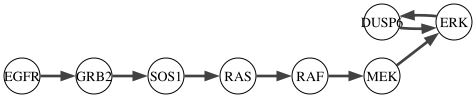

In [6]:
plot(confident, graph_attr={'rankdir': 'LR'})

`confident` is a live, read-only view: it follows changes to the parent graph
and to the selection. To get a separate graph that you can edit, use
`confident.materialize()`.

## Add an annotation

Write through `anet.attrs` to change the graph:

In [7]:
anet.attrs.update('nodes', {'ERK': {'label': 'ERK response'}})
anet.uns['dataset'] = 'annnet synthetic tutorial network'
anet.attrs.row('nodes', 'ERK')

{'label': 'ERK response'}

Tables and rows from `anet.attrs` are detached copies. If you edit a returned
data frame, annnet does not change.

## Save and reopen

The native format keeps identities, annotations, and slice membership. The
example writes into a temporary directory; use your own path to keep the file.
The writer does not replace an existing file unless you give `overwrite=True`.

In [8]:
from pathlib import Path
from tempfile import TemporaryDirectory

with TemporaryDirectory() as directory:
    path = Path(directory) / 'analysis.annnet'
    anet.write(path)
    restored = an.read(path)

restored.attrs.row('nodes', 'ERK')

{'label': 'ERK response'}

## Next steps

Continue with [Annotations, selections, and views](guide/annotations-and-views.ipynb)
for filters and materialization, or with [Slices](guide/slices.ipynb) to attach
results for several conditions. The [Guide](guide/index.md) also covers the
graph model, layers, and computation and storage.